<a href="https://colab.research.google.com/github/harshbagul33-blip/CIE_2_Activity_2_Binary_Classification_Logistic_Regression-/blob/main/CIE_2_Activity_2_Loan_Approval_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, classification_report
)
from sklearn.dummy import DummyClassifier

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from google.colab import files
from pathlib import Path

dataset_url = "https://raw.githubusercontent.com/snehajangid/Loan_Prediction/main/train.csv"

try:
    df = pd.read_csv(dataset_url)
    print("Dataset downloaded successfully.")
except Exception as e:
    print("Automatic download failed. Please upload train.csv.")
    uploaded = files.upload()
    file_name = next(iter(uploaded))
    df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())

Dataset downloaded successfully.
Dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

Missing values:


,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14



Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


In [4]:
df = df.drop_duplicates().copy()

# Remove identifier and selected personal attributes from model inputs
columns_to_drop = [col for col in ["Loan_ID", "Gender", "Married"] if col in df.columns]
df = df.drop(columns=columns_to_drop)

# Convert target: Y = 1 (Approved), N = 0 (Not Approved)
df = df.dropna(subset=["Loan_Status"])
df["Loan_Status"] = df["Loan_Status"].map({"Y": 1, "N": 0})

print("Cleaned dataset shape:", df.shape)
print("\nTarget values:")
print(df["Loan_Status"].value_counts())

Cleaned dataset shape: (614, 10)

Target values:
Loan_Status
1    422
0    192
Name: count, dtype: int64


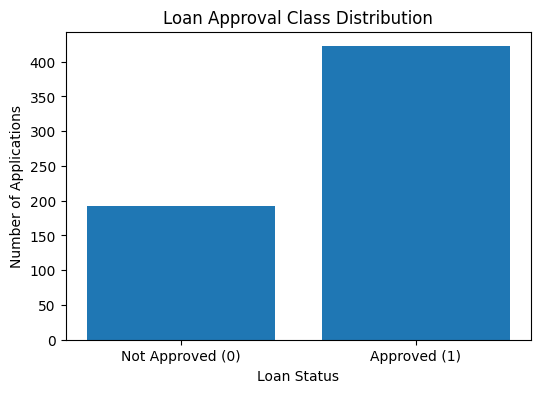

Approval rate: 68.73 %


In [5]:
class_counts = df["Loan_Status"].value_counts().sort_index()
class_names = ["Not Approved (0)", "Approved (1)"]

plt.figure(figsize=(6, 4))
plt.bar(class_names, [class_counts.get(0, 0), class_counts.get(1, 0)])
plt.title("Loan Approval Class Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.show()

print("Approval rate:", round((df["Loan_Status"] == 1).mean() * 100, 2), "%")

In [6]:
X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target classes:", sorted(y.unique()))

Numerical features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical features: ['Dependents', 'Education', 'Self_Employed', 'Property_Area']
Target classes: [np.int64(0), np.int64(1)]


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))
print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))

Training records: 491
Testing records: 123

Training class proportions:
Loan_Status
1    0.686354
0    0.313646
Name: proportion, dtype: float64

Testing class proportions:
Loan_Status
1    0.691057
0    0.308943
Name: proportion, dtype: float64


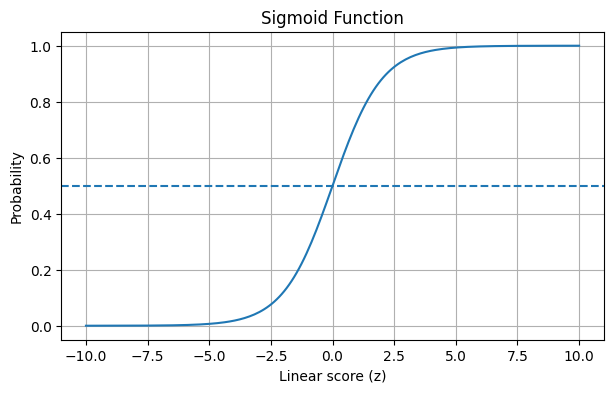

In [8]:
z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid)
plt.axhline(0.5, linestyle="--")
plt.title("Sigmoid Function")
plt.xlabel("Linear score (z)")
plt.ylabel("Probability")
plt.grid(True)
plt.show()

In [9]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [10]:
classifier = model.named_steps["classifier"]
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": classifier.coef_[0]
})
coefficients["Absolute Coefficient"] = coefficients["Coefficient"].abs()
coefficients = coefficients.sort_values("Absolute Coefficient", ascending=False)

print("Intercept:", classifier.intercept_[0])
display(coefficients)

print("A positive coefficient increases the model's estimated approval log-odds,")
print("while a negative coefficient decreases them, with other features held constant.")

Intercept: 0.6876908668666761


,Feature,Coefficient,Absolute Coefficient
4,num__Credit_History,1.239608,1.239608
14,cat__Property_Area_Semiurban,0.465766,0.465766
7,cat__Dependents_2,0.395025,0.395025
6,cat__Dependents_1,-0.364916,0.364916
13,cat__Property_Area_Rural,-0.305163,0.305163
5,cat__Dependents_0,-0.189431,0.189431
9,cat__Education_Graduate,0.180857,0.180857
10,cat__Education_Not Graduate,-0.179966,0.179966
8,cat__Dependents_3+,0.160213,0.160213
15,cat__Property_Area_Urban,-0.159712,0.159712


A positive coefficient increases the model's estimated approval log-odds,
while a negative coefficient decreases them, with other features held constant.


In [11]:
y_probability = model.predict_proba(X_test)[:, 1]
y_pred_05 = (y_probability >= 0.5).astype(int)

results = X_test.copy()
results["Actual_Status"] = y_test.values
results["Approval_Probability"] = y_probability
results["Predicted_Status_0.5"] = y_pred_05

display(results.head(10))

,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Actual_Status,Approval_Probability,Predicted_Status_0.5
150,0,Graduate,No,6277,0.0,118.0,360.0,0.0,Rural,0,0.073268,0
559,0,Graduate,No,4180,2306.0,182.0,360.0,1.0,Semiurban,1,0.846755,1
598,0,Graduate,Yes,9963,0.0,180.0,360.0,1.0,Rural,1,0.691709,1
235,1,Graduate,No,5500,1260.0,170.0,360.0,1.0,Rural,1,0.694511,1
145,0,Graduate,No,2330,4486.0,100.0,360.0,1.0,Semiurban,1,0.833075,1
191,0,Graduate,No,12000,0.0,164.0,360.0,1.0,Semiurban,0,0.862725,1
557,3+,Graduate,Yes,10139,0.0,260.0,360.0,1.0,Semiurban,1,0.871489,1
470,1,Graduate,Yes,3450,2079.0,162.0,360.0,1.0,Semiurban,1,0.784809,1
88,0,Graduate,No,8566,0.0,210.0,360.0,1.0,Urban,1,0.769074,1
386,0,Not Graduate,No,2346,1600.0,132.0,360.0,1.0,Semiurban,1,0.801330,1


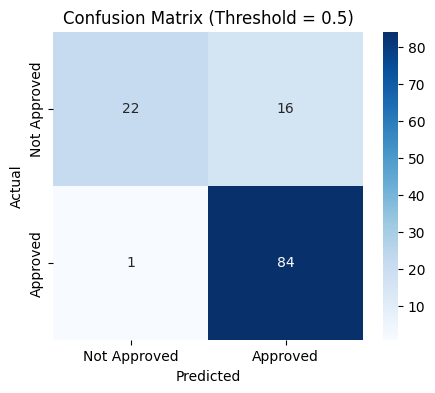

TN: 22 | FP: 16 | FN: 1 | TP: 84


In [12]:
cm = confusion_matrix(y_test, y_pred_05, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Approved", "Approved"],
            yticklabels=["Not Approved", "Approved"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Threshold = 0.5)")
plt.show()

print("TN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

In [13]:
def calculate_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0
    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall (Sensitivity)": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": specificity,
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

metrics_05 = calculate_metrics(y_test, y_probability, 0.5)
display(pd.DataFrame([metrics_05]).round(4))

print("Accuracy = (TP + TN) / (TP + TN + FP + FN)")
print("Precision = TP / (TP + FP)")
print("Recall = TP / (TP + FN)")
print("Specificity = TN / (TN + FP)")
print("F1-score = 2 × (Precision × Recall) / (Precision + Recall)")
print("ROC-AUC measures how well the model ranks positive cases above negative cases.")

,Threshold,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-score,ROC-AUC
0,0.5,0.8618,0.84,0.9882,0.5789,0.9081,0.8452


Accuracy = (TP + TN) / (TP + TN + FP + FN)
Precision = TP / (TP + FP)
Recall = TP / (TP + FN)
Specificity = TN / (TN + FP)
F1-score = 2 × (Precision × Recall) / (Precision + Recall)
ROC-AUC measures how well the model ranks positive cases above negative cases.


In [14]:
print(classification_report(
    y_test, y_pred_05,
    labels=[0, 1],
    target_names=["Not Approved", "Approved"],
    zero_division=0
))

              precision    recall  f1-score   support

Not Approved       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



In [15]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
model_accuracy = accuracy_score(y_test, y_pred_05)

print("Majority-class baseline accuracy:", round(baseline_accuracy, 4))
print("Logistic Regression accuracy:", round(model_accuracy, 4))

Majority-class baseline accuracy: 0.6911
Logistic Regression accuracy: 0.8618


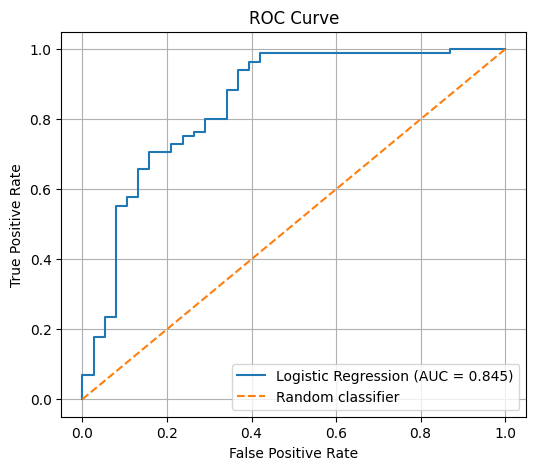

ROC-AUC: 0.8452


In [16]:
fpr, tpr, thresholds_roc = roc_curve(y_test, y_probability)
roc_auc = roc_auc_score(y_test, y_probability)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC:", round(roc_auc, 4))

In [17]:
threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    row = calculate_metrics(y_test, y_probability, threshold)
    threshold_rows.append(row)

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))

,Threshold,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-score,ROC-AUC
0,0.3,0.8537,0.8317,0.9882,0.5526,0.9032,0.8452
1,0.5,0.8618,0.8400,0.9882,0.5789,0.9081,0.8452
2,0.7,0.8049,0.8506,0.8706,0.6579,0.8605,0.8452


In [18]:
recommended_row = threshold_table.sort_values(
    by=["Precision", "Recall (Sensitivity)"],
    ascending=[False, False]
).iloc[0]

recommended_threshold = float(recommended_row["Threshold"])
print("Recommended threshold for this classroom comparison:", recommended_threshold)
print("Reason: it gives the highest precision among the tested thresholds,")
print("with recall used to break ties. Review the error costs before choosing a real threshold.")

Recommended threshold for this classroom comparison: 0.7
Reason: it gives the highest precision among the tested thresholds,
with recall used to break ties. Review the error costs before choosing a real threshold.


In [19]:
train_probability = model.predict_proba(X_train)[:, 1]
train_prediction = (train_probability >= 0.5).astype(int)

comparison = pd.DataFrame([
    {
        "Dataset": "Training",
        "Accuracy": accuracy_score(y_train, train_prediction),
        "Precision": precision_score(y_train, train_prediction, zero_division=0),
        "Recall": recall_score(y_train, train_prediction, zero_division=0),
        "F1-score": f1_score(y_train, train_prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_train, train_probability)
    },
    {
        "Dataset": "Testing",
        "Accuracy": accuracy_score(y_test, y_pred_05),
        "Precision": precision_score(y_test, y_pred_05, zero_division=0),
        "Recall": recall_score(y_test, y_pred_05, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_05, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability)
    }
])

display(comparison.round(4))

,Dataset,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Training,0.8004,0.7825,0.9822,0.8711,0.7643
1,Testing,0.8618,0.8400,0.9882,0.9081,0.8452


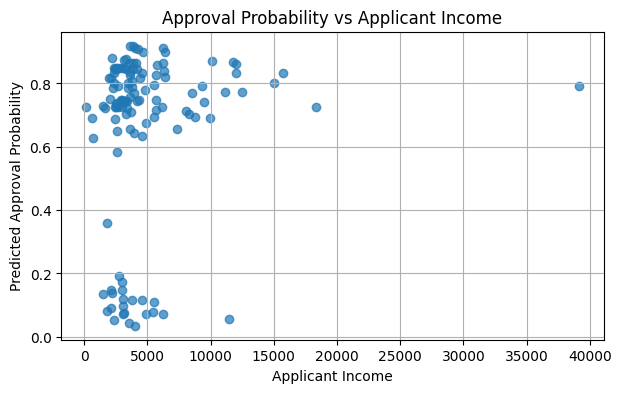

In [20]:
income_column = "ApplicantIncome"

if income_column in X_test.columns:
    plt.figure(figsize=(7, 4))
    plt.scatter(X_test[income_column], y_probability, alpha=0.7)
    plt.xlabel("Applicant Income")
    plt.ylabel("Predicted Approval Probability")
    plt.title("Approval Probability vs Applicant Income")
    plt.grid(True)
    plt.show()
else:
    print("ApplicantIncome is not available in this dataset.")

In [21]:
new_application = X_test.iloc[[0]].copy()

new_probability = model.predict_proba(new_application)[0, 1]
new_prediction = int(new_probability >= 0.5)

print("New application details:")
display(new_application)

print("Predicted approval probability:", round(new_probability, 4))
print("Predicted status:", "Approved" if new_prediction == 1 else "Not Approved")

New application details:


,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
150,0,Graduate,No,6277,0.0,118.0,360.0,0.0,Rural


Predicted approval probability: 0.0733
Predicted status: Not Approved
